In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf

prices = yf.download(
    ["V", "MA"],
    start="2016-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"].dropna()

log_prices = np.log(prices)

train = log_prices.loc["2016-01-01":"2021-12-31"]
test = log_prices.loc["2022-01-01":"2025-12-31"]

asset_returns = prices.pct_change()
test_returns = asset_returns.loc[test.index]

In [2]:
Y = train["MA"]
X = sm.add_constant(train["V"])

ols = sm.OLS(Y, X).fit()

static_alpha = ols.params["const"]
static_beta = ols.params["V"]

train_spread = (
    train["MA"]
    - static_alpha
    - static_beta * train["V"]
)

spread_mean = train_spread.mean()
spread_std = train_spread.std()

static_test_spread = (
    test["MA"]
    - static_alpha
    - static_beta * test["V"]
)

static_z = (
    static_test_spread - spread_mean
) / spread_std

static_beta_series = pd.Series(
    static_beta,
    index=test.index
)

In [3]:
window = 126

rolling_beta = []
rolling_z = []

for date in test.index:

    i = log_prices.index.get_loc(date)

    history = log_prices.iloc[i-window:i]

    Y_hist = history["MA"]
    X_hist = sm.add_constant(history["V"])

    model = sm.OLS(Y_hist, X_hist).fit()

    alpha_t = model.params["const"]
    beta_t = model.params["V"]

    historical_residuals = model.resid

    current_residual = (
        log_prices.loc[date, "MA"]
        - alpha_t
        - beta_t * log_prices.loc[date, "V"]
    )

    z_t = (
        current_residual
        - historical_residuals.mean()
    ) / historical_residuals.std()

    rolling_beta.append(beta_t)
    rolling_z.append(z_t)

rolling_beta = pd.Series(
    rolling_beta,
    index=test.index
)

rolling_z = pd.Series(
    rolling_z,
    index=test.index
)

In [4]:
q = 1e-5
Q = q * np.eye(2)

R = ols.mse_resid

theta = np.array([
    static_alpha,
    static_beta
])

P = np.eye(2)
I = np.eye(2)

In [5]:
for date in train.index:

    x_t = train.loc[date, "V"]
    y_t = train.loc[date, "MA"]

    H = np.array([[1.0, x_t]])

    theta_pred = theta.copy()
    P_pred = P + Q

    y_pred = float((H @ theta_pred)[0])

    error = y_t - y_pred

    S = float(
        (H @ P_pred @ H.T)[0, 0] + R
    )

    K = (P_pred @ H.T) / S

    theta = (
        theta_pred
        + K.flatten() * error
    )

    A = I - K @ H

    P = (
        A @ P_pred @ A.T
        + (K * R) @ K.T
    )

In [6]:
kalman_beta = []
kalman_z = []

for date in test.index:

    x_t = test.loc[date, "V"]
    y_t = test.loc[date, "MA"]

    H = np.array([[1.0, x_t]])

    theta_pred = theta.copy()
    P_pred = P + Q

    y_pred = float((H @ theta_pred)[0])

    error = y_t - y_pred

    S = float(
        (H @ P_pred @ H.T)[0, 0] + R
    )

    z_t = error / np.sqrt(S)

    kalman_beta.append(theta_pred[1])
    kalman_z.append(z_t)

    K = (P_pred @ H.T) / S

    theta = (
        theta_pred
        + K.flatten() * error
    )

    A = I - K @ H

    P = (
        A @ P_pred @ A.T
        + (K * R) @ K.T
    )

kalman_beta = pd.Series(
    kalman_beta,
    index=test.index
)

kalman_z = pd.Series(
    kalman_z,
    index=test.index
)

In [7]:
def generate_positions(z, entry=2.0):

    positions = []
    position = 0

    for value in z:

        if position == 0:

            if value > entry:
                position = -1

            elif value < -entry:
                position = 1

        elif position == 1:

            if value >= 0:
                position = 0

        elif position == -1:

            if value <= 0:
                position = 0

        positions.append(position)

    return pd.Series(
        positions,
        index=z.index
    )

In [8]:
static_position = generate_positions(static_z)
rolling_position = generate_positions(rolling_z)
kalman_position = generate_positions(kalman_z)

In [9]:
def make_weights(position, beta):

    denominator = 1 + beta.abs()

    weights = pd.DataFrame(
        index=position.index
    )

    weights["MA"] = (
        position / denominator
    )

    weights["V"] = (
        -position * beta / denominator
    )

    return weights

In [10]:
def run_backtest(
    z,
    beta,
    cost_bps=5
):

    position = generate_positions(z)

    weights = make_weights(
        position,
        beta
    )

    previous_weights = (
        weights.shift(1)
        .fillna(0)
    )

    gross_return = (
        previous_weights["MA"]
        * test_returns["MA"]
        +
        previous_weights["V"]
        * test_returns["V"]
    )

    turnover = (
        weights
        - weights.shift(1).fillna(0)
    ).abs().sum(axis=1)

    cost_rate = cost_bps / 10000

    net_return = (
        gross_return
        - cost_rate
        * turnover.shift(1).fillna(0)
    )

    return (
        net_return,
        position,
        turnover
    )

In [11]:
static_ret, static_pos, static_turn = run_backtest(
    static_z,
    static_beta_series
)

rolling_ret, rolling_pos, rolling_turn = run_backtest(
    rolling_z,
    rolling_beta
)

kalman_ret, kalman_pos, kalman_turn = run_backtest(
    kalman_z,
    kalman_beta
)

In [12]:
def performance_metrics(
    returns,
    position,
    turnover
):

    returns = returns.dropna()

    equity = (
        1 + returns
    ).cumprod()

    annual_return = (
        equity.iloc[-1]
        ** (252 / len(returns))
        - 1
    )

    annual_vol = (
        returns.std()
        * np.sqrt(252)
    )

    sharpe = (
        returns.mean()
        / returns.std()
        * np.sqrt(252)
        if returns.std() > 0
        else np.nan
    )

    drawdown = (
        equity
        / equity.cummax()
        - 1
    )

    max_drawdown = drawdown.min()

    entries = (
        (position != 0)
        & (position.shift(1).fillna(0) == 0)
    ).sum()

    return {
        "Annual Return": annual_return,
        "Sharpe": sharpe,
        "Max Drawdown": max_drawdown,
        "Turnover": turnover.sum(),
        "Trades": entries
    }

In [13]:
results = pd.DataFrame({
    "Static OLS": performance_metrics(
        static_ret,
        static_pos,
        static_turn
    ),

    "Rolling OLS": performance_metrics(
        rolling_ret,
        rolling_pos,
        rolling_turn
    ),

    "Kalman Filter": performance_metrics(
        kalman_ret,
        kalman_pos,
        kalman_turn
    )
}).T

results

,Annual Return,Sharpe,Max Drawdown,Turnover,Trades
Static OLS,0.014521,0.369001,-0.055218,7.000000,4.0
Rolling OLS,0.031192,0.669553,-0.053330,28.163502,13.0
Kalman Filter,0.000000,NaN,0.000000,0.000000,0.0


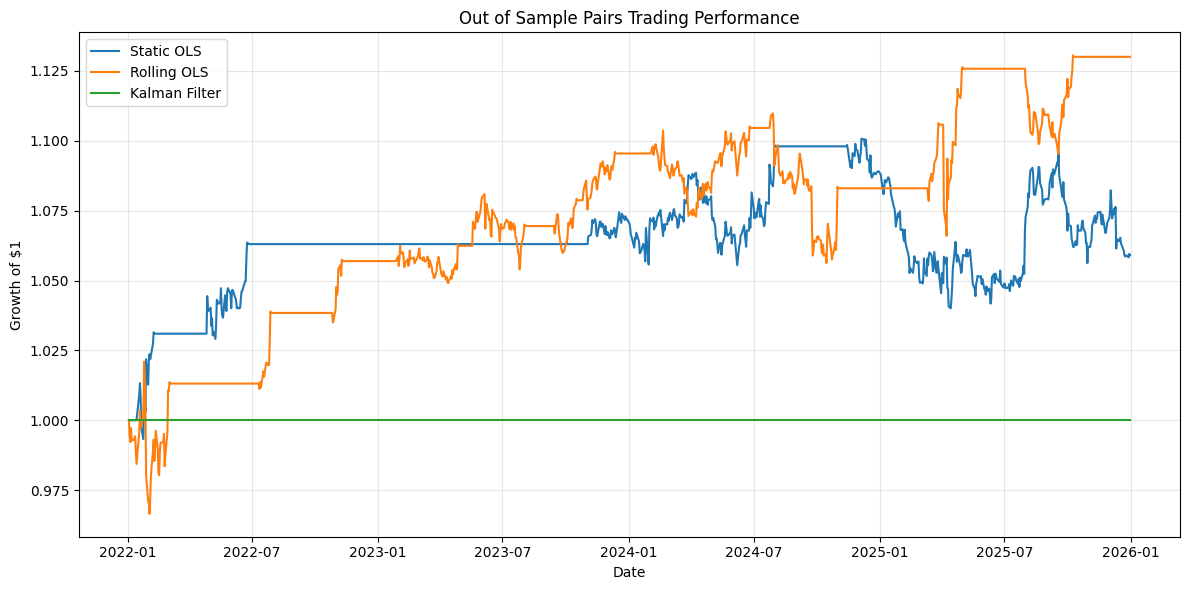

In [14]:
equity = pd.DataFrame({
    "Static OLS":
        (1 + static_ret.fillna(0)).cumprod(),

    "Rolling OLS":
        (1 + rolling_ret.fillna(0)).cumprod(),

    "Kalman Filter":
        (1 + kalman_ret.fillna(0)).cumprod()
})

plt.figure(figsize=(12, 6))

for model in equity.columns:
    plt.plot(
        equity.index,
        equity[model],
        label=model
    )

plt.title(
    "Out of Sample Pairs Trading Performance"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()